In [1]:
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

In [11]:
import anndata as ad
import colorcet as cc
import geopandas as gpd
import lazyslide as zs
import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
import squidpy as sq
from shapely import box
from spatialdata.models import ShapesModel
from spatialdata_io import visium_hd
from spatialleiden import spatialleiden, spatialleiden_multimodal
from wsidata import open_wsi

from utils import (
    DATA_DIR,
    RESULT_DIR,
    mm,
    remove_tick_and_label,
)

In [3]:
data_dir = DATA_DIR / "VisiumHD_CRC"
result_dir = RESULT_DIR / "VisiumHD_CRC"

seed = 42

## Load data

In [6]:
result_dir.mkdir(exist_ok=True, parents=True)

In [7]:
wsi = open_wsi(data_dir / "Visium_HD_Human_Colon_Cancer_tissue_image_pyramid.btf")

In [8]:
import json

scale_file = data_dir / "binned_outputs/square_016um/spatial/scalefactors_json.json"

with open(scale_file, "r") as f:
    scalefactors = json.load(f)

In [9]:
wsi.properties.mpp = scalefactors["microns_per_pixel"]
print("mpp:", scalefactors["microns_per_pixel"])

mpp: 0.27389195078106876


WSI: data/VisiumHD_CRC/Visium_HD_Human_Colon_Cancer_tissue_image_pyramid.btf
Reader: openslide
Dimensions: 48740×75250 (h×w), 11 Pyramids
Pixel physical size: 0.27389195078106876 MPP
SpatialData object
└── Images
      └── 'wsi_thumbnail': DataArray[cyx] (3, 839, 1295)
with coordinate systems:
    ▸ 'global', with elements:
        wsi_thumbnail (Images)
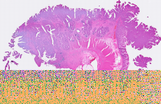

In [10]:
wsi

In [11]:
wsi.properties

Field,Value
shape,"[48740, 75250]"
n_level,11
level_shape,"[[48740, 75250], [24370, 37625], [12185, 18812], [6092, 9406], [3046, 4703], [1523, 2351], [761, 1175], [380, 587], [190, 293], [95, 146], [47, 73]]"
level_downsample,"[1.0, 2.0, 4.000053157559005, 8.00043461452707, 16.00086922905414, 32.00514135586678, 64.04492968378673, 128.2286828655967, 256.6761271780133, 514.2317952415285, 1033.921597201982]"
mpp,0.27389195078106876
magnification,None
bounds,"[0, 0, 75250, 48740]"


## Define ROI

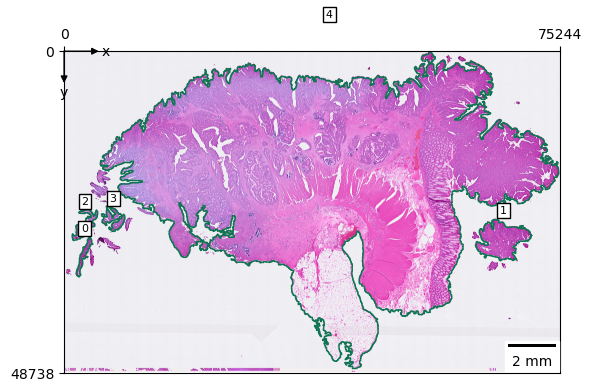

In [12]:
zs.pp.find_tissues(wsi, level=3, detect_holes=False)

zs.pl.tissue(wsi)

In [13]:
bin_coord = (
    pd.read_parquet(
        data_dir / "binned_outputs/square_008um/spatial/tissue_positions.parquet"
    )
    .set_index("barcode")
    .loc[lambda df: df["in_tissue"] == 1]
)

bin_coord.head()

,in_tissue,array_row,array_col,pxl_row_in_fullres,pxl_col_in_fullres
barcode,,,,,
s_008um_00000_00000-1,1,0,0,22367.134394,40609.482784
s_008um_00000_00001-1,1,0,1,22367.526449,40638.675813
s_008um_00000_00002-1,1,0,2,22367.918505,40667.868872
s_008um_00000_00003-1,1,0,3,22368.310561,40697.061961
s_008um_00000_00004-1,1,0,4,22368.702618,40726.255079


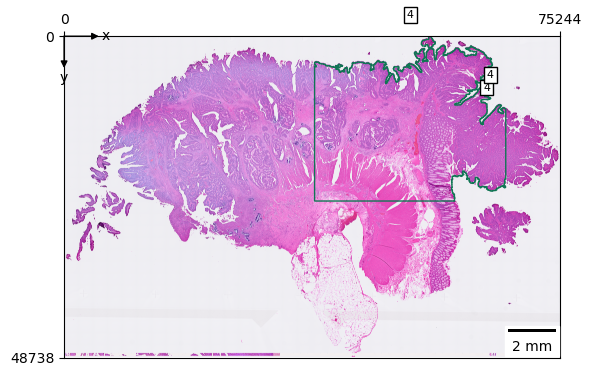

In [16]:
# crop to roughly the area of the ST data


def clip_roi(gdf, roi):
    return gdf[gdf.intersects(roi)].clip(roi, keep_geom_type=True)


wsi.shapes["tissues"] = ShapesModel.parse(
    clip_roi(wsi.shapes["tissues"], box(38_000, 0, 67_000, 25_000))
)

zs.pl.tissue(wsi)

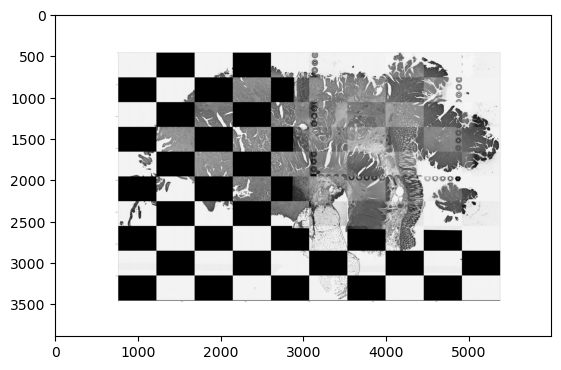

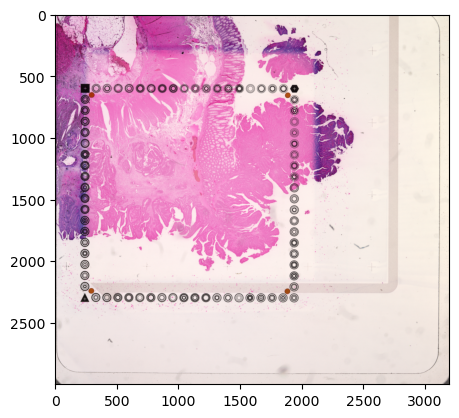

In [17]:
%matplotlib inline

# confirm tissue area
import matplotlib.image as mpimg

im_dir = data_dir / "binned_outputs/square_008um/spatial"

for img_name in ["aligned_tissue_image.jpg", "cytassist_image.tiff"]:
    _ = plt.imshow(mpimg.imread(im_dir / img_name))
    plt.show()

In [18]:
zs.pp.tile_tissues(wsi, 256)

In [17]:
tile_shapes = wsi.shapes["tiles"]
tile_shapes.to_parquet(result_dir / "tiles_shapes.parquet", index=False)

## Feature extraction

We want to extract features of tiles and map them back to "cells" (bins).
Potential approaches are:
- Center a small tile on each cell; however that doesn't scale well computationally
- Have larger tiles and map multiple cells to the same tile; The issue for SpatialLeiden concretely will be that all cells within the same tile will have the same feature vector. Thus when building the neighbr graph cells will be connected either to all cells within the same tile or to a random subset. The H&E would therefore basically only capture the spatial closeness of cells (i.e. located in the same tile) but not the actual feature space.

Alternatively, we can try a slightly more convoluted approach. We extract features of each tile and build a kNN graph (with self-loops) directly in the tile space before mapping back to the cells. This will lead to all cells within a tile being connected to all cells of a tile neighboring it in the kNN graph. To avoid having very dense graphs we can for each cell randomly subsample it to be connected to _n_ cells (optionally from each of the connected tiles) instead of all cells.

Output()

WSI: data/VisiumHD_CRC/Visium_HD_Human_Colon_Cancer_tissue_image_pyramid.btf
Reader: openslide
Dimensions: 48740×75250 (h×w), 11 Pyramids
Pixel physical size: 0.27389195078106876 MPP
SpatialData object
├── Images
│     └── 'wsi_thumbnail': DataArray[cyx] (3, 839, 1295)
├── Shapes
│     ├── 'tiles': GeoDataFrame shape: (8563, 3) (2D shapes)
│     └── 'tissues': GeoDataFrame shape: (3, 2) (2D shapes)
└── Tables
      └── 'uni2_tiles': AnnData (8563, 1536)
with coordinate systems:
    ▸ 'global', with elements:
        wsi_thumbnail (Images), tiles (Shapes), tissues (Shapes)
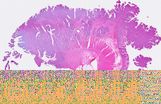

In [18]:
zs.tl.feature_extraction(wsi, "uni2")

wsi

In [19]:
n_pcs = 15

tiles = wsi.tables["uni2_tiles"]

sc.pp.scale(tiles)
sc.pp.pca(tiles, n_comps=n_pcs, random_state=seed)

tiles

AnnData object with n_obs × n_vars = 8563 × 1536
    obs: 'tile_id', 'library_id'
    var: 'mean', 'std'
    uns: 'spatialdata_attrs', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'

In [20]:
sc.pp.neighbors(tiles, random_state=seed)
sc.tl.umap(tiles, random_state=seed)

3 resolutions UMAP + spatialplot

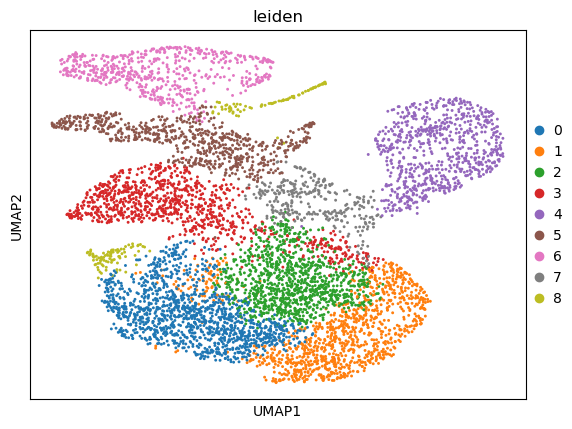

In [22]:
# use flavor leidenalg (not igraph) to be more comparable to SpatialLeiden later on
sc.tl.leiden(
    tiles, flavor="leidenalg", resolution=0.4, directed=False, random_state=seed
)

sc.pl.umap(tiles, color="leiden")

In [23]:
tile_shapes = gpd.read_parquet(result_dir / "tiles_shapes.parquet")

In [28]:
tiles.obsm["spatial"] = np.column_stack(
    (tile_shapes.geometry.centroid.x.values, tile_shapes.geometry.centroid.y.values)
)

sq.gr.spatial_neighbors(tiles, coord_type="grid", n_neighs=8)

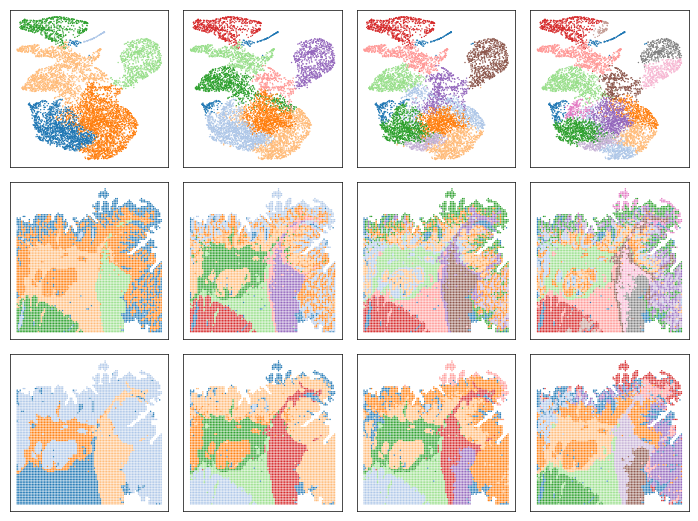

In [29]:
import matplotlib.pyplot as plt
import pandas as pd
import scanpy as sc

resolutions = [0.2, 0.4, 0.6, 0.8]
for res in resolutions:
    sc.tl.leiden(
        tiles,
        flavor="leidenalg",
        resolution=res,
        directed=False,
        random_state=seed,
        key_added=f"leiden_res_{res}",
    )

for res in resolutions:
    spatialleiden(
        tiles,
        resolution=res,
        directed=False,
        n_iterations=5,
        layer_ratio=0.5,
        random_state=seed,
        key_added=f"sl_res_{res}",
    )

umap_coords = tiles.obsm["X_umap"]
umap_data_list = []
for res in resolutions:
    df_temp = pd.DataFrame(
        {
            "x": umap_coords[:, 0],
            "y": umap_coords[:, 1],
            "leiden": tiles.obs[f"leiden_res_{res}"].astype(str),
            "resolution": f"{res}",
            "plot_type": "UMAP",
        }
    )
    umap_data_list.append(df_temp)

spatial_coords = pd.DataFrame(
    {
        "x": tile_shapes.geometry.centroid.x,
        "y": tile_shapes.geometry.centroid.y,
    }
)

leiden_spatial_data_list = []
for res in resolutions:
    df_spatial = pd.DataFrame(
        {
            "x": spatial_coords["x"].values,
            "y": spatial_coords["y"].values,
            "leiden": tiles.obs[f"leiden_res_{res}"].astype(str),
            "resolution": f"{res}",
            "plot_type": "Leiden Spatial",
        }
    )
    leiden_spatial_data_list.append(df_spatial)

sl_spatial_data_list = []
for res in resolutions:
    df_spatial = pd.DataFrame(
        {
            "x": spatial_coords["x"].values,
            "y": spatial_coords["y"].values,
            "leiden": tiles.obs[f"sl_res_{res}"].astype(str),
            "resolution": f"{res}",
            "plot_type": "SpatialLeiden",
        }
    )
    sl_spatial_data_list.append(df_spatial)

plot_data = pd.concat(
    umap_data_list + leiden_spatial_data_list + sl_spatial_data_list, ignore_index=True
)

scatter_kwargs = {
    "s": 1,
    "alpha": 1,
    "linewidth": 0,
}

g = sns.FacetGrid(
    plot_data,
    row="plot_type",
    col="resolution",
    aspect=1,
    height=180 * mm / 4,
    legend_out=True,
    row_order=["UMAP", "Leiden Spatial", "SpatialLeiden"],
    sharex=False,
    sharey=False,
)

_ = g.map_dataframe(
    sns.scatterplot,
    x="x",
    y="y",
    hue="leiden",
    palette="tab20",
    legend=False,
    rasterized=True,
    **scatter_kwargs,
)

_ = g.set_titles("")

for ax in g.axes.flat:
    remove_tick_and_label(ax)

    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

    for spine in ax.spines.values():
        spine.set_edgecolor("black")
        spine.set_linewidth(0.5)

for ax in g.axes[1, :]:
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymax, ymin)

for ax in g.axes[2, :]:
    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymax, ymin)

plt.tight_layout()
plt.savefig("leiden_SL_combined_umap_HE.pdf", dpi=600, bbox_inches="tight")
plt.show()

In [30]:
labels = pd.DataFrame(tiles.obsm["spatial"], columns=["y", "x"], index=tiles.obs_names)
labels["leiden_he"] = tiles.obs["leiden"]

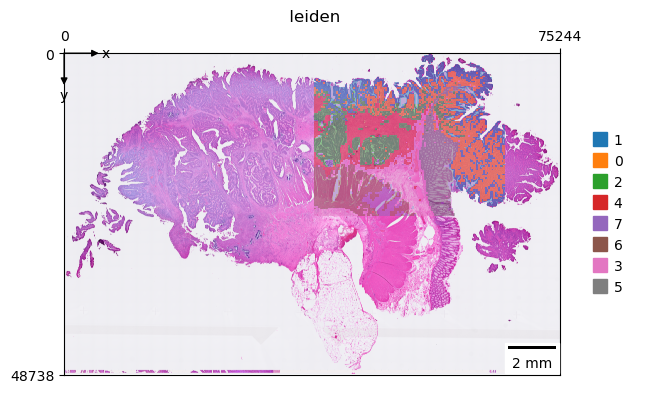

In [22]:
zs.pl.tiles(
    wsi,
    feature_key="uni2",
    color="leiden",
    alpha=0.5,
    palette=tiles.uns["leiden_colors"],
    show_contours=False,
)

In [23]:
tiles.write_h5ad(result_dir / "tiles.h5ad")

del wsi

## Load ST data

In [33]:
st_data = visium_hd(data_dir, bin_size=8)
st_data

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/lazyslide2/lib/python3.12/site-packages/anndata/_core/anndata.py:1813: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


SpatialData object
├── Images
│     ├── 'Visium_HD_Human_Colon_Cancer_full_image': DataTree[cyx] (3, 48740, 75250), (3, 24370, 37625), (3, 12185, 18812), (3, 6092, 9406), (3, 3046, 4703)
│     ├── 'Visium_HD_Human_Colon_Cancer_hires_image': DataArray[cyx] (3, 3886, 6000)
│     └── 'Visium_HD_Human_Colon_Cancer_lowres_image': DataArray[cyx] (3, 389, 600)
├── Shapes
│     └── 'Visium_HD_Human_Colon_Cancer_square_008um': GeoDataFrame shape: (545913, 1) (2D shapes)
└── Tables
      └── 'square_008um': AnnData (545913, 18085)
with coordinate systems:
    ▸ 'Visium_HD_Human_Colon_Cancer', with elements:
        Visium_HD_Human_Colon_Cancer_full_image (Images), Visium_HD_Human_Colon_Cancer_hires_image (Images), Visium_HD_Human_Colon_Cancer_lowres_image (Images), Visium_HD_Human_Colon_Cancer_square_008um (Shapes)
    ▸ 'Visium_HD_Human_Colon_Cancer_downscaled_hires', with elements:
        Visium_HD_Human_Colon_Cancer_hires_image (Images), Visium_HD_Human_Colon_Cancer_square_008um (Shapes)
   

In [34]:
bin_shapes = st_data.shapes["Visium_HD_Human_Colon_Cancer_square_008um"]
bin_shapes.to_parquet(result_dir / "square_008um_shapes.parquet", index=True)

In [35]:
adata = st_data.tables["square_008um"]

del st_data

adata.var = (
    adata.var.drop(columns=["feature_types", "genome"])
    .reset_index(names="gene_name")
    .set_index("gene_ids")
)
adata.obsm["spatial_array"] = adata.obs[["array_row", "array_col"]].to_numpy()
adata.X = adata.X.astype("int32")

In [36]:
# mitochondrial genes
adata.var["mt"] = adata.var["gene_name"].str.startswith("MT-")
# hemoglobin genes
adata.var["hb"] = adata.var["gene_name"].str.contains("^HB[^(P)]")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "hb"], inplace=True, log1p=True)

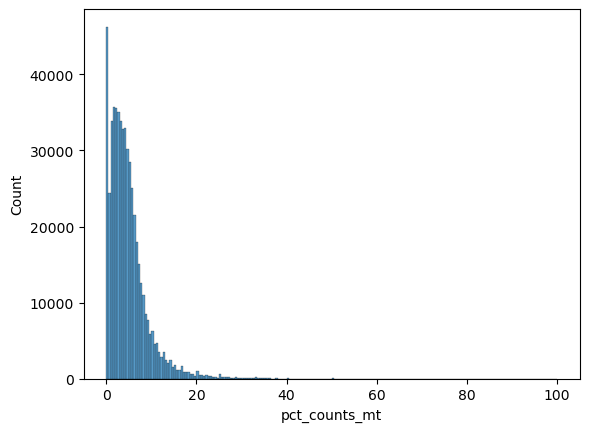

In [37]:
_ = sns.histplot(data=adata.obs, x="pct_counts_mt", bins=200)

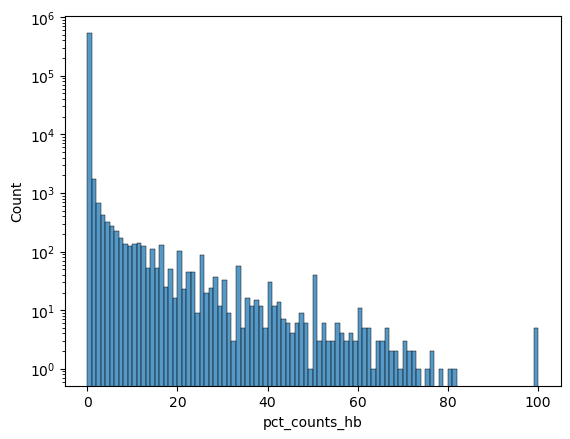

In [38]:
_ = sns.histplot(data=adata.obs, x="pct_counts_hb", bins=100, log=True)

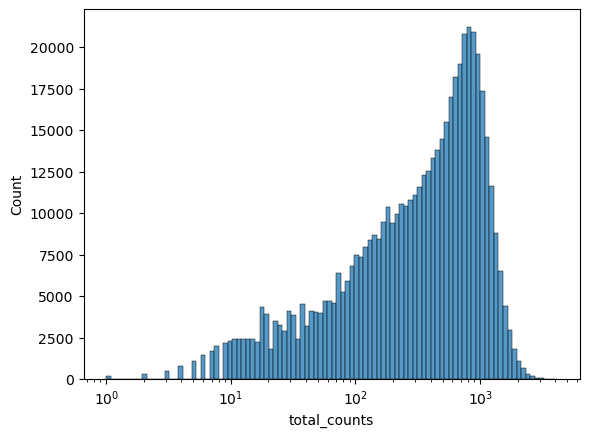

In [39]:
_ = sns.histplot(data=adata.obs, x="total_counts", bins=100, log_scale=True)

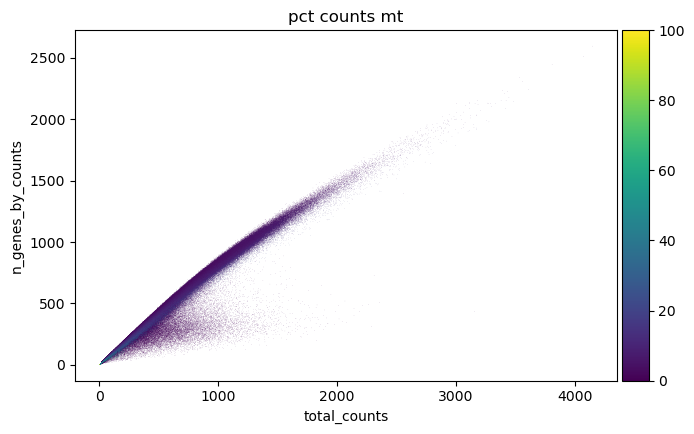

In [40]:
sc.pl.scatter(adata, "total_counts", "n_genes_by_counts", color="pct_counts_mt")

In [41]:
sc.pp.filter_cells(adata, min_genes=50)
sc.pp.filter_cells(adata, min_counts=100)
sc.pp.filter_genes(adata, min_cells=50)

In [43]:
adata.layers["counts"] = adata.X.copy()

sc.pp.normalize_total(adata)
sc.pp.log1p(adata)

sc.pp.highly_variable_genes(
    adata, n_top_genes=2_000, flavor="seurat_v3", layer="counts"
)

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/lazyslide2/lib/python3.12/site-packages/scanpy/preprocessing/_highly_variable_genes.py:75: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  warnings.warn(


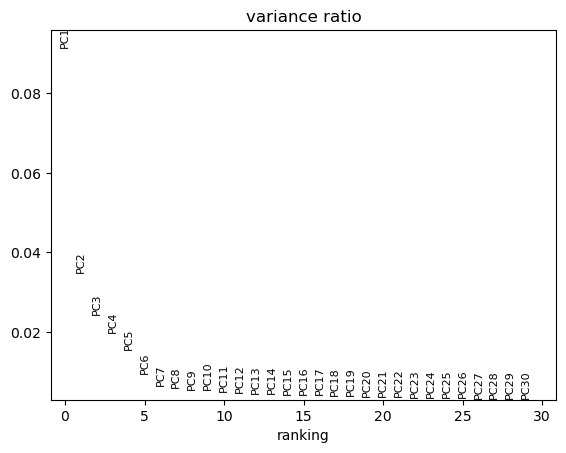

In [44]:
n_pcs = 30
sc.pp.pca(adata, n_comps=n_pcs, random_state=seed)

sc.pl.pca_variance_ratio(adata, n_pcs=n_pcs)

In [45]:
sc.pp.neighbors(adata, random_state=seed)
sc.tl.umap(adata, random_state=seed)

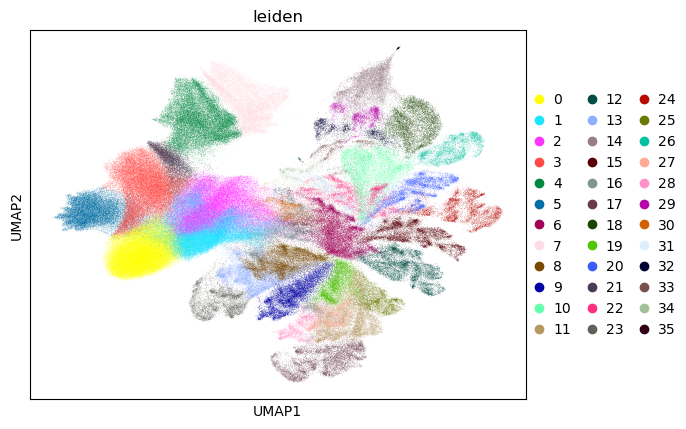

In [46]:
sc.tl.leiden(
    adata,
    flavor="leidenalg",
    directed=False,
    resolution=1,
    n_iterations=10,
    random_state=seed,
)

sc.pl.umap(adata, color="leiden")

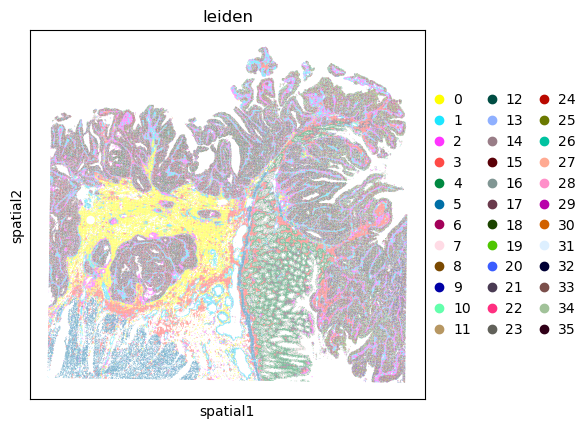

In [47]:
sc.pl.spatial(adata, color="leiden", spot_size=25)

In [39]:
adata.write_h5ad(result_dir / "bins8.h5ad")

## Merge with ST data

In [48]:
# load all data
adata = ad.read_h5ad(result_dir / "bins8.h5ad")
tiles = ad.read_h5ad(result_dir / "tiles.h5ad")

bin_shapes = gpd.read_parquet(result_dir / "square_008um_shapes.parquet")
tile_shapes = gpd.read_parquet(result_dir / "tiles_shapes.parquet")

In [19]:
# TODO map using closest centroid + intersect?
# which also works for sliding window approaches when tiling
bin_centroids = bin_shapes.copy()
bin_centroids["geometry"] = bin_centroids.geometry.centroid

id_mapping = pd.DataFrame(
    bin_centroids.sjoin(tile_shapes, how="inner", predicate="within").drop(
        columns=["geometry", "index_right"]
    )
)
id_mapping = (
    adata.obs[["location_id"]]
    .join(id_mapping, on="location_id", how="inner")
    .drop(columns="location_id")
)

id_mapping = (
    id_mapping.join(tiles.obs.reset_index().set_index("tile_id"), on="tile_id")[
        ["index"]
    ]
    .reset_index(names="bins")
    .set_index("index")
)
del bin_centroids, bin_shapes, tile_shapes

In [20]:
# to have approx the same number of neighbors after mapping tiles to cells
# we will reduce the kNN graph to 5 neighbors including self-loops
sc.pp.neighbors(tiles, n_neighbors=4, random_state=seed, method="gauss")

In [21]:
# subset to bins with both RNA and H&E
adata = adata[id_mapping["bins"], :].copy()

In [22]:
# remove unneeded attributes
del tiles.obsm, tiles.varm

bins_image = tiles[id_mapping.index, :].copy()
bins_image.obs_names = id_mapping["bins"]

bins_image.obs_names_make_unique()

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/lazyslide2/lib/python3.12/site-packages/anndata/_core/anndata.py:1811: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


In [23]:
import numpy as np
from scipy.sparse import csr_matrix


def downsample_rows(X: csr_matrix, n: int, *, random_state=None) -> csr_matrix:
    """
    Downsample each row of a CSR sparse array to contain at most `n` nonzero elements.
    If a row has fewer than `n` elements, it is left unchanged.
    """
    if not isinstance(X, csr_matrix):
        raise TypeError("X must be a scipy.sparse.csr_matrix")

    rng = np.random.default_rng(random_state)
    rows, cols, data = [], [], []

    for i in range(X.shape[0]):
        row_start, row_end = X.indptr[i], X.indptr[i + 1]
        row_indices = X.indices[row_start:row_end]
        row_data = X.data[row_start:row_end]

        if len(row_indices) > n:
            chosen = rng.choice(len(row_indices), size=n, replace=False)
            row_indices = row_indices[chosen]
            row_data = row_data[chosen]

        rows.extend([i] * len(row_indices))
        cols.extend(row_indices)
        data.extend(row_data)

    return csr_matrix((data, (rows, cols)), shape=X.shape)


bins_image.obsp["connectivities_sampled"] = downsample_rows(
    bins_image.obsp["connectivities"], 15, random_state=42
)

In [19]:
mdata = md.MuData({"rna": adata, "HE": bins_image})
mdata.write_h5mu(result_dir / "crc.h5mu")
mdata

MuData object with n_obs × n_vars = 417237 × 18398
  2 modalities
    rna:	417237 x 16862
      obs:	'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'n_counts', 'leiden'
      var:	'gene_name', 'mt', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
      uns:	'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatialdata_attrs', 'umap'
      obsm:	'X_pca', 'X_umap', 'spatial', 'spatial_array'
      varm:	'PCs'
      layers:	'counts'
      obsp:	'connectivities', 'distances'
    HE:	417237 x 1536
      obs:	'tile_id', 'library_id', 'leiden'
      var:	'mean', 'std'
      uns:	'leiden', 'leiden_colors', 'neighbors', 'pca', 'spatialdata_attrs', 'umap'
      obsp:	'connectivities', 'distances', 'connectivities_sampled'

## SpatialLeiden multimodal

In [4]:
mdata = md.read_h5mu(result_dir / "crc.h5mu")
mdata

MuData object with n_obs × n_vars = 417237 × 18398
  2 modalities
    rna:	417237 x 16862
      obs:	'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'n_genes', 'n_counts', 'leiden'
      var:	'gene_name', 'mt', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
      uns:	'hvg', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'pca', 'spatialdata_attrs', 'umap'
      obsm:	'X_pca', 'X_umap', 'spatial', 'spatial_array'
      varm:	'PCs'
      layers:	'counts'
      obsp:	'connectivities', 'distances'
    HE:	417237 x 1536
      obs:	'tile_id', 'library_id', 'leiden'
      var:	'mean', 'std'
      uns:	'leiden', 'leiden_colors', 'neighbors', 'pca', 'spatialdata_attrs', 'umap'
      obsp:	'connectivities', 'connectivities_sampled', 'distances'

In [5]:
mdata.obsm["spatial"] = mdata["rna"].obsm["spatial_array"]

sq.gr.spatial_neighbors(mdata, coord_type="grid", n_neighs=8)

In [6]:
%%time


spatialleiden_multimodal(
    mdata,
    resolution=0.55,
    directed=False,
    n_iterations=5,
    layer_weights={"rna": 1.5, "HE": 0.5, "spatial": 2},
    neighbors_key={"rna": "connectivities", "HE": "connectivities_sampled"},
    random_state=seed,
    key_added=f"res_{res}",
)

CPU times: user 5min 19s, sys: 5.25 s, total: 5min 24s
Wall time: 5min 22s


In [7]:
labels = pd.DataFrame(mdata.obsm["spatial"], columns=["y", "x"], index=mdata.obs_names)
labels["spatialleiden_res55"] = mdata.obs["res_0.55"]

/home/jovyan/spacehack-v3/projects/7_SpatialLeiden_multiX/SpatialLeiden2_Study/conda_envs/lazyslide2/lib/python3.12/site-packages/seaborn/axisgrid.py:854: UserWarning: The palette list has more values (256) than needed (5), which may not be intended.
  func(*plot_args, **plot_kwargs)


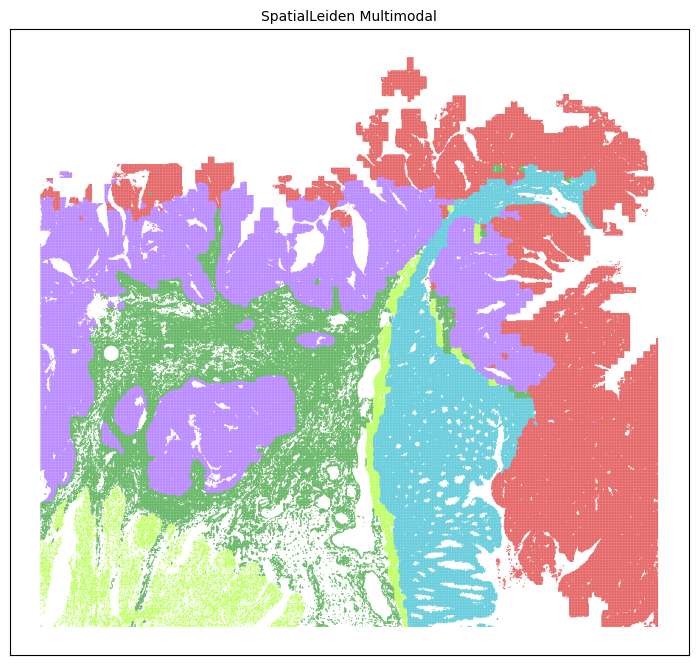

In [9]:
plot_data_list = []
scatter_kwargs = {
    "s": 0.25,
    "alpha": 1,
    "linewidth": 0,
}

columns = ["spatialleiden_res55"]

for col in columns:
    res_value = col.replace("spatialleiden_res", "")

    temp_df = pd.DataFrame(
        {
            "x": labels["x"],
            "y": labels["y"],
            "cluster": labels[col],
            "resolution": f"res={res_value}",
        }
    )
    plot_data_list.append(temp_df)

plot_data = pd.concat(plot_data_list, ignore_index=True)

g = sns.FacetGrid(
    plot_data,
    col="resolution",
    col_order=[f"res={r}" for r in ["55"]],
    aspect=1,
    height=180 * mm,
    legend_out=True,
)

# Map the scatter plot
_ = g.map_dataframe(
    sns.scatterplot,
    x="x",
    y="y",
    hue="cluster",
    palette=cc.glasbey,
    rasterized=True,
    **scatter_kwargs,
)

_ = g.set(aspect=1)
_ = g.set_titles("SpatialLeiden Multimodal")

for ax in g.axes.flat:
    remove_tick_and_label(ax)
    # ax.invert_yaxis()
    # Add frame on all 4 sides
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

plt.tight_layout()
plt.savefig(
    "spatial_leiden_resolutions_multimodal_55_2.pdf", dpi=300, bbox_inches="tight"
)
plt.show()

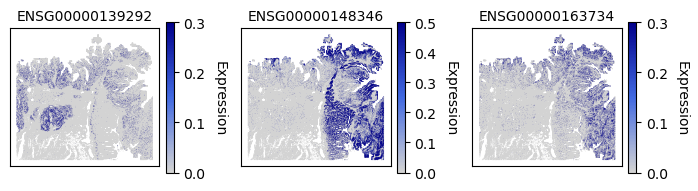

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

colors = ["#D3D3D3", "#4169E1", "#00008B"]
n_bins = 100
cmap_name = "grey_to_darkblue"
grey_blue_cmap = LinearSegmentedColormap.from_list(cmap_name, colors, N=n_bins)

# Gene list
genes = ["ENSG00000139292", "ENSG00000148346", "ENSG00000163734"]
vmax_values = [0.3, 0.5, 0.3]  # vmax for each gene

plot_data_list = []
scatter_kwargs = {
    "s": 0.05,
    "alpha": 1,
    "linewidth": 0,
}

for gene in genes:
    temp_df = pd.DataFrame(
        {
            "x": mdata["rna"].obsm["spatial_array"][:, 1],
            "y": mdata["rna"].obsm["spatial_array"][:, 0],
            "expression": mdata["rna"][:, gene].X.toarray().flatten()
            if hasattr(mdata["rna"][:, gene].X, "toarray")
            else mdata["rna"][:, gene].X.flatten(),
            "gene": gene,
        }
    )
    plot_data_list.append(temp_df)

plot_data = pd.concat(plot_data_list, ignore_index=True)

g = sns.FacetGrid(
    plot_data,
    col="gene",
    col_wrap=3,
    aspect=1,
    height=180 * mm / 3 / 1,
    legend_out=True,
)

for ax, gene, vmax in zip(g.axes.flat, genes, vmax_values):
    gene_data = plot_data[plot_data["gene"] == gene]

    scatter = ax.scatter(
        gene_data["x"],
        gene_data["y"],
        c=gene_data["expression"],
        cmap=grey_blue_cmap,  # Use custom colormap
        vmin=0,
        vmax=vmax,
        s=scatter_kwargs["s"],
        alpha=scatter_kwargs["alpha"],
        linewidth=scatter_kwargs["linewidth"],
        rasterized=True,
    )

    cbar = plt.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("Expression", rotation=270, labelpad=15)

_ = g.set(aspect=1)
_ = g.set_titles(col_template="{col_name}")

for ax in g.axes.flat:
    ax.set(xticklabels=[], yticklabels=[], xlabel=None, ylabel=None)
    ax.tick_params(left=False, bottom=False)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)


plt.tight_layout()
plt.savefig("spatial_gene_expression_v2.pdf", dpi=600, bbox_inches="tight")
plt.show()

In [23]:
labels = pd.DataFrame(mdata.obsm["spatial"], columns=["y", "x"], index=mdata.obs_names)
labels["spatialleiden"] = mdata.obs["spatialleiden"]
labels["leiden_rna"] = mdata["rna"].obs["leiden"]
labels["leiden_he"] = mdata["HE"].obs["leiden"]

In [35]:
%%time

spatialleiden_multimodal(
    mdata,
    resolution=1,
    directed=False,
    n_iterations=5,
    layer_weights={"rna": 1.5, "HE": 0.5, "spatial": 2},
    neighbors_key={"rna": "connectivities", "HE": "connectivities_sampled"},
    random_state=seed,
)

IOStream.flush timed out
IOStream.flush timed out


CPU times: user 6min 13s, sys: 6.87 s, total: 6min 19s
Wall time: 6min 16s


In [36]:
labels = pd.DataFrame(mdata.obsm["spatial"], columns=["y", "x"], index=mdata.obs_names)
labels["spatialleiden"] = mdata.obs["spatialleiden"]
labels["leiden_rna"] = mdata["rna"].obs["leiden"]
labels["leiden_he"] = mdata["HE"].obs["leiden"]

/tmp/ipykernel_3497/284058920.py:8: UserWarning: The palette list has more values (256) than needed (8), which may not be intended.
  sns.scatterplot(
/tmp/ipykernel_3497/284058920.py:8: UserWarning: The palette list has more values (256) than needed (21), which may not be intended.
  sns.scatterplot(
/tmp/ipykernel_3497/284058920.py:8: UserWarning: The palette list has more values (256) than needed (13), which may not be intended.
  sns.scatterplot(


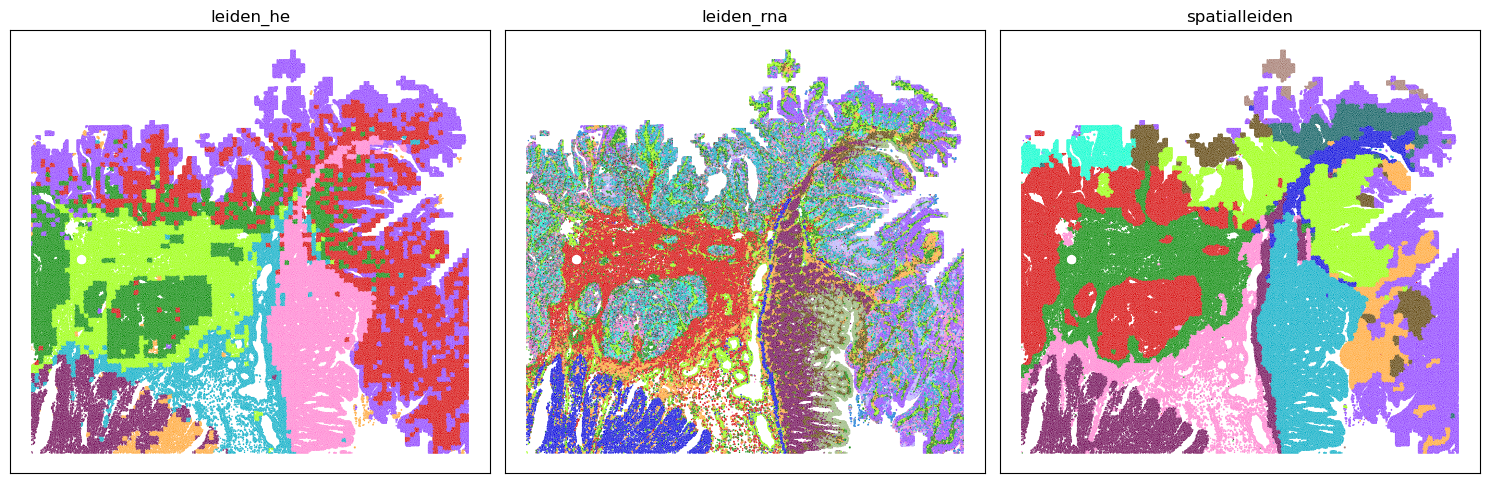

In [37]:
columns = ["leiden_he", "leiden_rna", "spatialleiden"]

fig, axs = plt.subplots(ncols=3, figsize=(15, 5))

for ax, c in zip(axs, columns):
    sns.scatterplot(
        data=labels, x="x", y="y", hue=c, s=1, ax=ax, palette=cc.glasbey, legend=False
    )

    ax.set(aspect=1, title=c)
    ax.set(xticklabels=[], yticklabels=[], xlabel=None, ylabel=None)
    ax.tick_params(left=False, bottom=False)

fig.tight_layout()

In [31]:
mdata["rna"].obsp["spatial_connectivities"] = mdata.obsp["spatial_connectivities"]

3 res + 3 layer_ratio 
9 figures 3x3 grid 


In [38]:
%%time

spatialleiden(
    mdata["rna"],
    resolution=0.8,
    directed=False,
    n_iterations=5,
    layer_ratio=1,
    random_state=seed,
)

IOStream.flush timed out


CPU times: user 3min 4s, sys: 4.52 s, total: 3min 9s
Wall time: 3min 8s


In [39]:
labels = pd.DataFrame(mdata.obsm["spatial"], columns=["y", "x"], index=mdata.obs_names)
labels["spatialleiden"] = mdata["rna"].obs["spatialleiden"]
labels["leiden_rna"] = mdata["rna"].obs["leiden"]

/tmp/ipykernel_3497/2014990112.py:8: UserWarning: The palette list has more values (256) than needed (21), which may not be intended.
  sns.scatterplot(
/tmp/ipykernel_3497/2014990112.py:8: UserWarning: The palette list has more values (256) than needed (8), which may not be intended.
  sns.scatterplot(


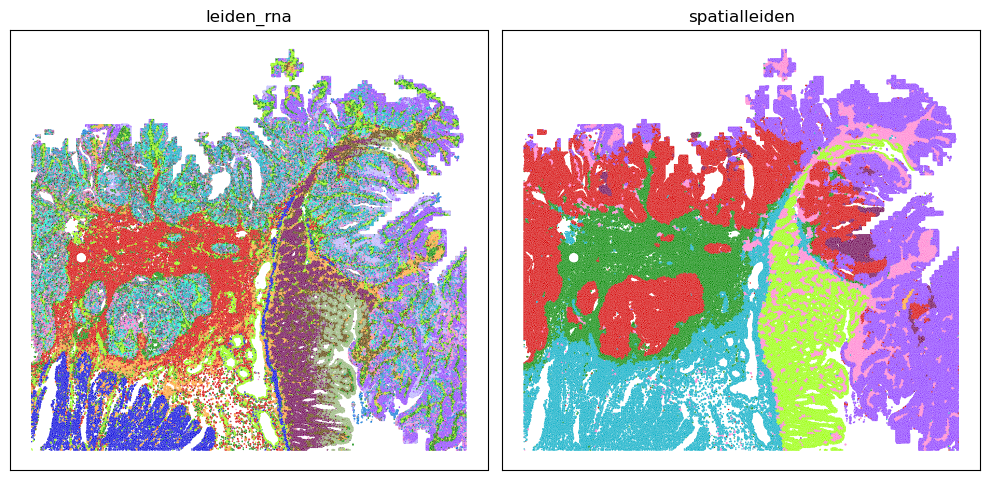

In [40]:
columns = ["leiden_rna", "spatialleiden"]

fig, axs = plt.subplots(ncols=2, figsize=(10, 5))

for ax, c in zip(axs, columns):
    sns.scatterplot(
        data=labels, x="x", y="y", hue=c, s=1, ax=ax, palette=cc.glasbey, legend=False
    )

    ax.set(aspect=1, title=c)
    ax.set(xticklabels=[], yticklabels=[], xlabel=None, ylabel=None)
    ax.tick_params(left=False, bottom=False)

fig.tight_layout()

multiple res + spatial layers

In [32]:
%%time

resolutions = [0.6, 0.8, 1.2]
layer_ratios = [0.8, 1, 1.2]

for res in resolutions:
    for lr in layer_ratios:
        spatialleiden(
            mdata["rna"],
            resolution=res,
            directed=False,
            n_iterations=5,
            layer_ratio=lr,
            random_state=seed,
            key_added=f"res_{res}_layerratio_{lr}",
        )

CPU times: user 24min 12s, sys: 33.3 s, total: 24min 45s
Wall time: 24min 37s


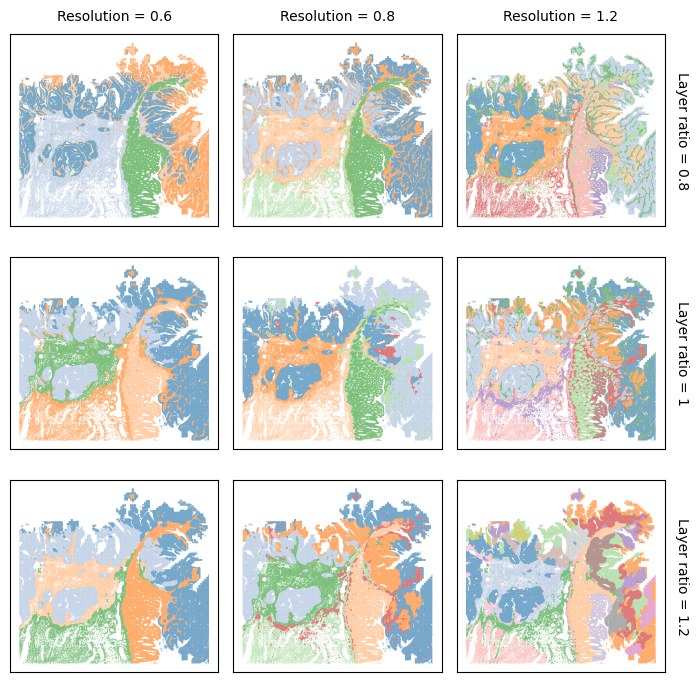

In [47]:
plot_data_list = []
scatter_kwargs = {
    "s": 0.03,
    "alpha": 1,
    "linewidth": 0,
}

resolutions = [0.6, 0.8, 1.2]
layer_ratios = [0.8, 1, 1.2]

for res in resolutions:
    for lr in layer_ratios:
        key = f"res_{res}_layerratio_{lr}"
        temp_df = pd.DataFrame(
            {
                "x": mdata["rna"].obsm["spatial_array"][:, 1],
                "y": mdata["rna"].obsm["spatial_array"][:, 0],
                "cluster": mdata["rna"].obs[key],
                "resolution": f"res={res}",
                "layer_ratio": f"lr={lr}",
            }
        )
        plot_data_list.append(temp_df)

plot_data = pd.concat(plot_data_list, ignore_index=True)

g = sns.FacetGrid(
    plot_data,
    row="layer_ratio",
    col="resolution",
    aspect=1,
    height=180 * mm / 3 / 1,
    legend_out=True,
)

_ = g.map_dataframe(
    sns.scatterplot,
    x="x",
    y="y",
    hue="cluster",
    palette="tab20",
    rasterized=True,
    **scatter_kwargs,
)

_ = g.set(aspect=1)
_ = g.set_titles("")

for ax in g.axes.flat:
    remove_tick_and_label(ax)
    ax.spines["top"].set_visible(True)
    ax.spines["right"].set_visible(True)
    ax.spines["bottom"].set_visible(True)
    ax.spines["left"].set_visible(True)

for ax, res in zip(g.axes[0], resolutions):
    ax.set_title(f"Resolution = {res}", fontsize=10, pad=10)

for ax, lr in zip(g.axes[:, -1], layer_ratios):
    ax.text(
        1.05,
        0.5,
        f"Layer ratio = {lr}",
        transform=ax.transAxes,
        fontsize=10,
        va="center",
        rotation=-90,
    )

plt.tight_layout()
plt.savefig(
    "Visium_CRC_RNA_res_cols_lr_rows_Supp_Fig8.pdf", dpi=600, bbox_inches="tight"
)
plt.show()